In [8]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Quantum K-Means Results Analysis
군집별 개수           : [ 98 102]
특징 공간 중심의 크기 : (2, 8)
군집 내 제곱거리 합   : 41.19978
생성 정답과 비교한 ARI: 0.4328
검증 통과: 양자 충실도와 특징 공간 거리 관계가 수학적으로 성립합니다.


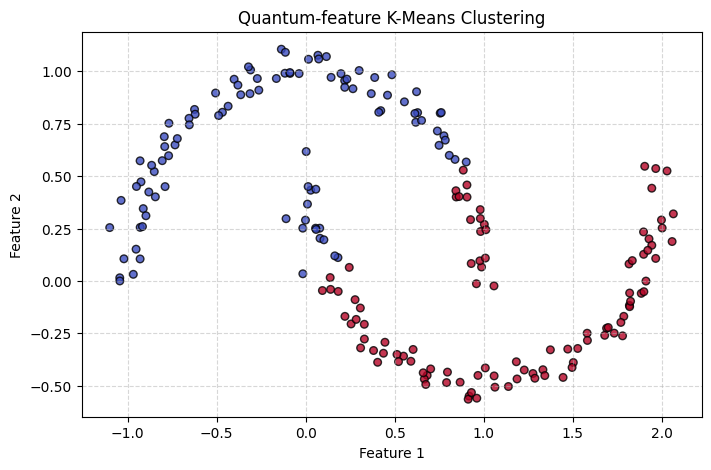

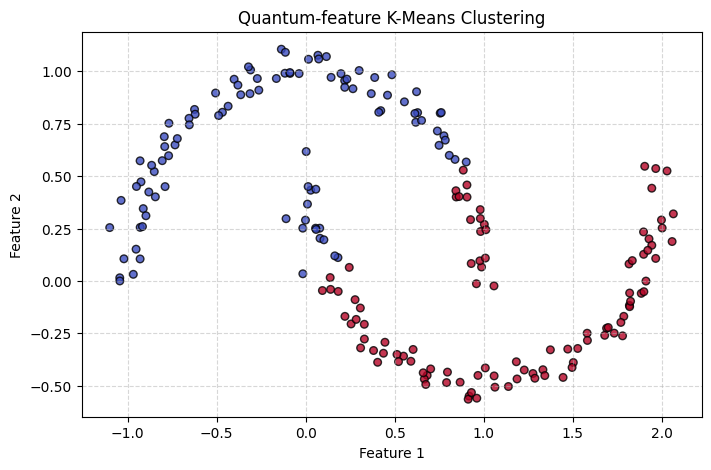


회로 인코딩에 따라 군집 결과가 달라집니다. 성능 개선은 별도 비교가 필요합니다.


In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


# ==============================================================================
# STEP 2. 비선형 데이터셋(Make Moons) 생성 및 정규화
# ==============================================================================
# 200개의 초승달 모양 비선형 분류 데이터를 생성하고,
# 1큐비트 회로의 회전 각도로 사용하기 위해 값을 [0, π] 범위로 정규화합니다.
X, y = make_moons(n_samples=200, noise=0.05, random_state=42)
angles = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(X)


# ==============================================================================
# STEP 3. 양자 상태 인코딩 함수 정의
# ==============================================================================
# 2차원 입력 좌표를 1큐비트의 RY, RZ 게이트 각도로 주입하여
# 고차원 힐베르트 공간의 양자 상태(Statevector)로 변환합니다.
def quantum_state(x):
    qc = QuantumCircuit(1)
    qc.ry(x[0], 0)
    qc.rz(x[1], 0)
    return Statevector.from_instruction(qc).data

# 전체 데이터셋을 양자 상태로 변환
states = np.array([quantum_state(x) for x in angles])


# ==============================================================================
# STEP 4. 밀도행렬(Density Matrix) 기반 특징 벡터 추출
# ==============================================================================
# 순수 양자 상태의 밀도행렬(Outer Product)을 계산하고,
# 실수부와 허수부를 이어붙여(Concatenate) 고전 K-Means가 처리할 수 있는 특징 벡터로 변환합니다.
density = np.array([np.outer(s, s.conj()).ravel() for s in states])
features = np.concatenate([density.real, density.imag], axis=1)


# ==============================================================================
# STEP 5. 고전 K-Means 알고리즘을 이용한 군집화 실행
# ==============================================================================
# 변환된 양자 특징 공간(Quantum Feature Space)에서 2개의 군집(n_clusters=2)으로 분류합니다.
model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(features)
labels = model.labels_


# ==============================================================================
# STEP 6. 결과 분석 및 수학적 성질 검증 (Assertions)
# ==============================================================================
print("=" * 60)
print("Quantum K-Means Results Analysis")
print("=" * 60)
print("군집별 개수           :", np.bincount(labels))
print("특징 공간 중심의 크기 :", model.cluster_centers_.shape)
print("군집 내 제곱거리 합   :", round(float(model.inertia_), 6))
print("생성 정답과 비교한 ARI:", round(adjusted_rand_score(y, labels), 4))

# 수학적 성질 검증: 순수상태 밀도행렬 간 제곱거리는 2 * (1 - 충실도)와 같음을 확인
fidelity = abs(np.vdot(states[0], states[1])) ** 2
assert np.isclose(np.sum((features[0] - features[1])**2), 2 * (1 - fidelity)), "충실도 거리 관계식 불일치!"
assert len(np.unique(labels)) == 2 and len(labels) == len(X), "군집 결과 개수 오류!"
print("검증 통과: 양자 충실도와 특징 공간 거리 관계가 수학적으로 성립합니다.")


# ==============================================================================
# STEP 7. 결과 시각화 (스위프트 산점도)
# ==============================================================================
# 군집화된 결과를 색상으로 구분하여 2차원 산점도로 시각화합니다.
fig, ax = plt.subplots(figsize=(8, 5))

scatter = ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=30, edgecolor='k', alpha=0.8)
ax.set_title("Quantum-feature K-Means Clustering")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.grid(True, linestyle="--", alpha=0.5)

display(fig)
plt.show()

print("\n" + "=" * 60)
print("회로 인코딩에 따라 군집 결과가 달라집니다. 성능 개선은 별도 비교가 필요합니다.")
print("=" * 60)